In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"

ablation = pd.read_csv(REPORTS_DIR / "ablation_results.csv")
model_comparison = pd.read_csv(REPORTS_DIR / "model_comparison.csv")
boosting_results = pd.read_csv(REPORTS_DIR / "boosting_tuning_comparison.csv")
logistic_tuning = pd.read_csv(REPORTS_DIR / "tuning_results.csv")

print("Ablation results:", ablation.shape)
print("Initial model comparison:", model_comparison.shape)
print("Boosting tuning results:", boosting_results.shape)
print("Logistic Regression tuning results:", logistic_tuning.shape)

Ablation results: (2, 14)
Initial model comparison: (3, 11)
Boosting tuning results: (2, 8)
Logistic Regression tuning results: (5, 21)


In [2]:
display(ablation)

,configuration,feature_count,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,original_features,9,0.839143,0.007200,0.145853,0.009049,0.639416,0.036715,0.237474,0.014004,0.790966,0.016791,0.211201,0.023515
1,engineered_features,17,0.857314,0.007015,0.164610,0.010636,0.648175,0.041097,0.262463,0.016070,0.801465,0.017606,0.231269,0.033241


In [3]:
original = ablation.loc[
    ablation["configuration"] == "original_features"
].iloc[0]

engineered = ablation.loc[
    ablation["configuration"] == "engineered_features"
].iloc[0]

metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "pr_auc_mean"]

improvement = pd.DataFrame({
    "Metric": metrics,
    "Original": [original[m] for m in metrics],
    "Engineered": [engineered[m] for m in metrics],
})

improvement["Absolute Improvement"] = improvement["Engineered"] - improvement["Original"]

display(improvement.round(4))

,Metric,Original,Engineered,Absolute Improvement
0,accuracy_mean,0.8391,0.8573,0.0182
1,precision_mean,0.1459,0.1646,0.0188
2,recall_mean,0.6394,0.6482,0.0088
3,f1_mean,0.2375,0.2625,0.0250
4,roc_auc_mean,0.7910,0.8015,0.0105
5,pr_auc_mean,0.2112,0.2313,0.0201


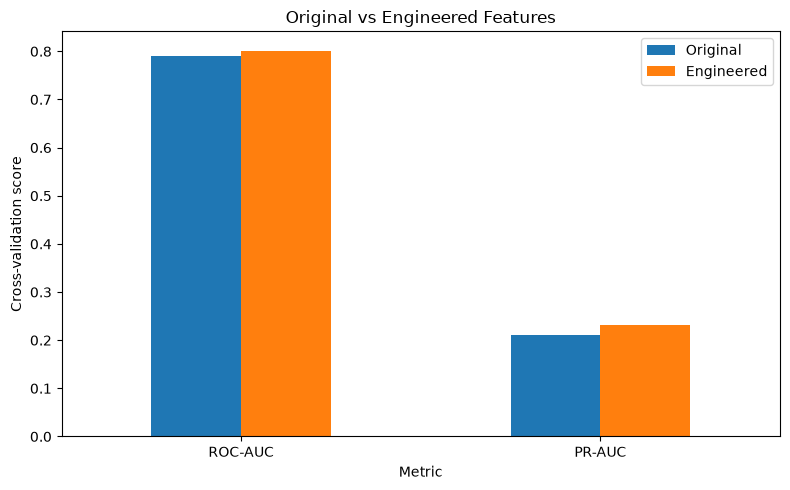

In [4]:
plot_data = improvement[
    improvement["Metric"].isin(["roc_auc_mean", "pr_auc_mean"])
].copy()

plot_data["Metric"] = plot_data["Metric"].map({
    "roc_auc_mean": "ROC-AUC",
    "pr_auc_mean": "PR-AUC",
})

plot_data = plot_data.set_index("Metric")[["Original", "Engineered"]]

plot_data.plot(kind="bar", figsize=(8, 5))
plt.title("Original vs Engineered Features")
plt.ylabel("Cross-validation score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
display(
    boosting_results.sort_values(
        "validation_pr_auc",
        ascending=False
    )
)

,model,best_cv_pr_auc,validation_pr_auc,validation_roc_auc,validation_precision,validation_recall,validation_f1,best_params
1,XGBoost,0.248871,0.290474,0.845686,0.440000,0.074830,0.127907,"{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha..."
0,LightGBM,0.246447,0.275362,0.853952,0.444444,0.027211,0.051282,"{'subsample': 0.9, 'reg_lambda': 0, 'num_leave..."


In [6]:
display(model_comparison)

,model,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.164610,0.009513,0.648175,0.036758,0.262463,0.014374,0.801465,0.015747,0.231269,0.029732
1,LightGBM,0.180487,0.016840,0.459854,0.056916,0.258832,0.024681,0.757235,0.022662,0.202652,0.024035
2,XGBoost,0.168907,0.007798,0.529927,0.032512,0.256049,0.011643,0.757801,0.016733,0.198325,0.016821


In [8]:
display(
    logistic_tuning.sort_values(
        "mean_test_score",
        ascending=False
    )[
        [
            "param_classifier__C",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
)

,param_classifier__C,mean_test_score,std_test_score,rank_test_score
3,10.00,0.231328,0.029657,1
4,100.00,0.231312,0.029656,2
2,1.00,0.231269,0.029732,3
1,0.10,0.230956,0.029915,4
0,0.01,0.224854,0.031590,5


In [9]:
feature_group_ablation = pd.read_csv(
    REPORTS_DIR / "feature_group_ablation.csv"
)

display(
    feature_group_ablation[
        [
            "configuration",
            "feature_count",
            "precision_mean",
            "recall_mean",
            "f1_mean",
            "roc_auc_mean",
            "pr_auc_mean",
            "pr_auc_delta",
        ]
    ].round(4)
)

,configuration,feature_count,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean,pr_auc_delta
0,original_features,9,0.1459,0.6394,0.2375,0.7910,0.2112,0.0000
1,ratio_features,10,0.1453,0.6380,0.2366,0.7907,0.2116,0.0004
2,log_features,11,0.1466,0.6394,0.2385,0.7912,0.2091,-0.0021
3,retry_error_features,12,0.1655,0.6482,0.2636,0.7999,0.2356,0.0244
4,time_features,11,0.1443,0.6394,0.2354,0.7924,0.2076,-0.0036
5,all_engineered_features,17,0.1646,0.6482,0.2625,0.8015,0.2313,0.0201


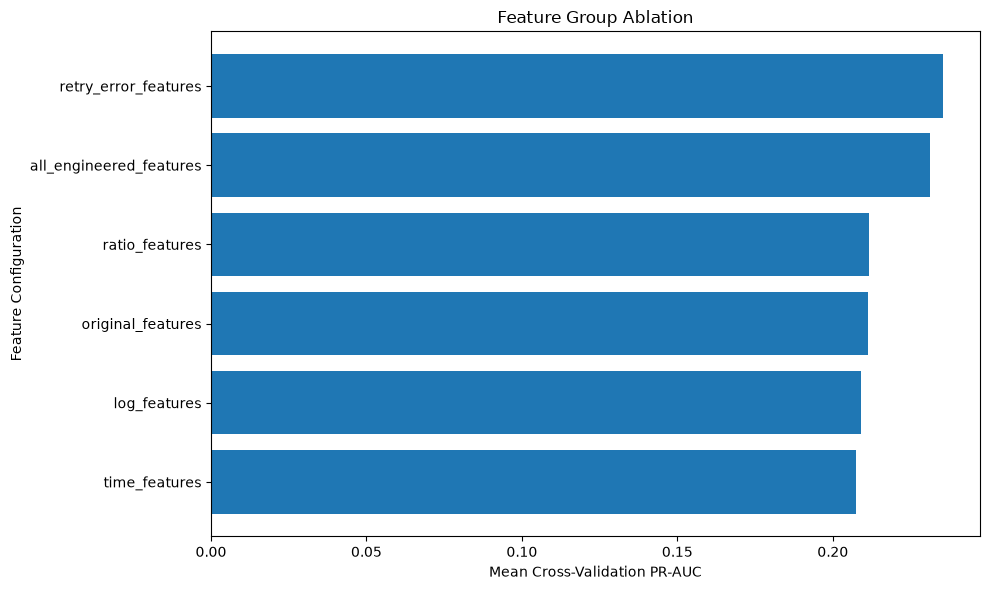

In [10]:
plot_data = feature_group_ablation.sort_values(
    "pr_auc_mean",
    ascending=True,
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["configuration"],
    plot_data["pr_auc_mean"],
)
plt.xlabel("Mean Cross-Validation PR-AUC")
plt.ylabel("Feature Configuration")
plt.title("Feature Group Ablation")
plt.tight_layout()
plt.show()